<a href="https://colab.research.google.com/github/bgeethagayathri2-del/Face-detection-OpenCV/blob/main/Face_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Image shape: (512, 512, 3)
minNeighbors=1: 2 face(s) found
minNeighbors=5: 1 face(s) found
minNeighbors=10: 1 face(s) found


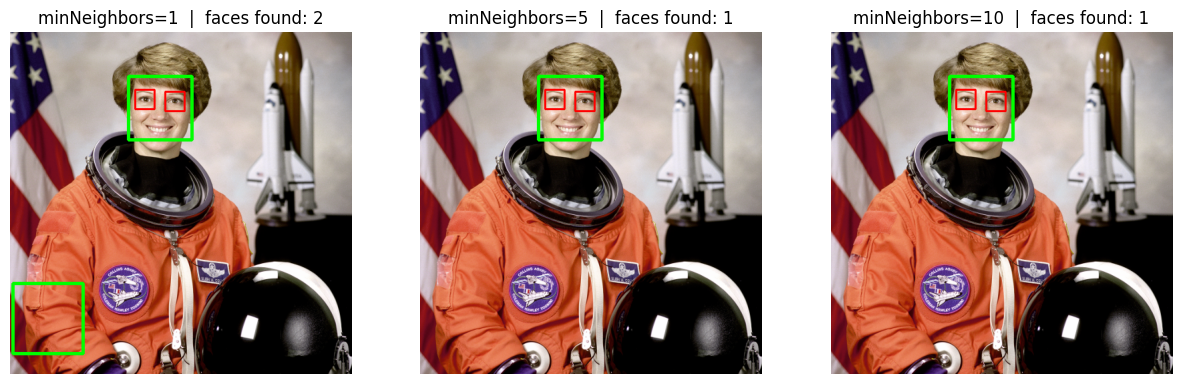

In [1]:
# Face Detection using OpenCV (Haar Cascade)
import cv2
import matplotlib.pyplot as plt
from skimage import data

# 1. Load a sample photo that comes with scikit-image (an astronaut portrait)
img_rgb = data.astronaut()
print("Image shape:", img_rgb.shape)

# 2. Load OpenCV's pre-trained face and eye detectors
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_eye.xml")

# 3. Function that finds faces and eyes and draws boxes
def detect(image_rgb, scale=1.1, neighbors=5):
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(
        gray, scaleFactor=scale, minNeighbors=neighbors, minSize=(30, 30)
    )
    out = image_rgb.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 3)       # green box = face
        eyes = eye_cascade.detectMultiScale(gray[y:y + h, x:x + w], 1.1, 5)
        for (ex, ey, ew, eh) in eyes:
            cv2.rectangle(out, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 0, 0), 2)  # blue box = eye
    return out, len(faces)

# 4. Show the effect of the minNeighbors setting
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, n in zip(axes, [1, 5, 10]):
    result, count = detect(img_rgb, neighbors=n)
    ax.imshow(result)
    ax.set_title(f"minNeighbors={n}  |  faces found: {count}")
    ax.axis("off")
    print(f"minNeighbors={n}: {count} face(s) found")
plt.show()